## 0 · Ambiente e diretórios

Execute o Notebook `01_RAG_DATA_PREPARATION.ipynb` até a exportação. Este notebook lê somente os arquivos produzidos na etapa anterior e grava relatórios, índice e avaliação. Para execução local, defina `PLN_AVALIACAO_DIR` para a raiz da avaliação.


## 0 · Ambiente e diretórios

Execute o notebook `01_RAG_DATA_PREPARATION_SEM_COLETA.ipynb` até a exportação. Este notebook **lê somente** os arquivos em `application/data/rag/` e grava relatórios, índice e avaliação dentro de `application/`. Para execução local, aponte `PLN_AVALIACAO_DIR` para a pasta `avaliacao`.

In [16]:
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter, defaultdict
import hashlib
import json
import logging
import os
import re
import unicodedata

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount('/content/drive')

def resolve_workspace_root():
    """Resolve a raiz no Colab, VS Code ou execução por linha de comando."""
    if IN_COLAB:
        return Path('/content/drive/MyDrive/IFSP-ADS/ultimo_periodo/tc_2/avaliacao')
    configured = os.environ.get('PLN_AVALIACAO_DIR', '').strip()
    if configured:
        return Path(configured).expanduser().resolve()
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / 'corpus').exists() or (candidate / 'application').exists():
            return candidate
    return Path.cwd().resolve()

AVALIACAO_DIR = resolve_workspace_root()
APPLICATION_DIR = AVALIACAO_DIR / 'application'
RAG_DIR = APPLICATION_DIR / 'data' / 'rag'
DOC_DIR = RAG_DIR / 'documents'
REFERENCE_DIR = RAG_DIR / 'reference'
EVAL_DIR = APPLICATION_DIR / 'data' / 'evaluation'
ARTIFACTS_DIR = APPLICATION_DIR / 'artifacts' / 'retrieval'
REPORT_DIR = APPLICATION_DIR / 'reports'
FIG_DIR = REPORT_DIR / 'figures'
LOG_DIR = APPLICATION_DIR / 'logs'

for directory in (EVAL_DIR, ARTIFACTS_DIR, REPORT_DIR, FIG_DIR, LOG_DIR):
    directory.mkdir(parents=True, exist_ok=True)

DOC_PATH = DOC_DIR / 'pokemon_rag_documents.jsonl'
RECORD_PATH = DOC_DIR / 'pokemon_rag_records.jsonl'
ALIASES_PATH = REFERENCE_DIR / 'translation_aliases_ptbr_en.json'
QUERY_PATH = EVAL_DIR / 'evaluation_queries.csv'
QRELS_PATH = EVAL_DIR / 'evaluation_qrels.csv'
EVAL_KS = (1, 3, 5, 10)
TOP_K_DEMO = 5
RUN_AT = datetime.now(timezone.utc).isoformat()

logger = logging.getLogger('pokemon_retrieval')
logger.handlers.clear()
logger.setLevel(logging.INFO)
logger.propagate = False
formatter = logging.Formatter('%(asctime)s | %(levelname)s | %(message)s')
fh = logging.FileHandler(LOG_DIR / '02_retrieval_and_evaluation.log', encoding='utf-8')
fh.setFormatter(formatter)
logger.addHandler(fh)
logger.addHandler(logging.StreamHandler())
logger.info('Início Notebook 02 | origem=%s', DOC_PATH)
print('Documentos de entrada:', DOC_PATH)
print('Artefatos de recuperação:', ARTIFACTS_DIR)
print('Avaliação:', EVAL_DIR)


Início Notebook 02 | origem=/content/drive/MyDrive/IFSP-ADS/ultimo_periodo/tc_2/avaliacao/application/data/rag/documents/pokemon_rag_documents.jsonl


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Documentos de entrada: /content/drive/MyDrive/IFSP-ADS/ultimo_periodo/tc_2/avaliacao/application/data/rag/documents/pokemon_rag_documents.jsonl
Artefatos de recuperação: /content/drive/MyDrive/IFSP-ADS/ultimo_periodo/tc_2/avaliacao/application/artifacts/retrieval
Avaliação: /content/drive/MyDrive/IFSP-ADS/ultimo_periodo/tc_2/avaliacao/application/data/evaluation


## 1 · Entrada: documentos temáticos prontos

O Notebook 01 já construiu `content` (texto legível para futura geração) e `retrieval_text` (texto para recuperação). Aqui validamos os arquivos e fixamos uma **ordem determinística**, que será mantida entre documentos e linhas das matrizes. **Não refazemos o pré-processamento do Trabalho 1.**

In [17]:
def load_jsonl(path):
    if not path.is_file():
        raise FileNotFoundError(
            f'Não encontrei {path}. Execute antes o 01_RAG_DATA_PREPARATION_SEM_COLETA.ipynb.'
        )
    with path.open(encoding='utf-8') as handle:
        return [json.loads(line) for line in handle if line.strip()]

required_document_keys = {
    'document_id', 'pokemon_id', 'pokemon_name', 'section',
    'content', 'retrieval_text', 'source_file'
}
documents = load_jsonl(DOC_PATH)
records = load_jsonl(RECORD_PATH)
if not documents:
    raise ValueError('A coleção de documentos está vazia.')

for idx, doc in enumerate(documents):
    missing = required_document_keys - doc.keys()
    if missing:
        raise ValueError(f'Documento {idx} sem campos obrigatórios: {missing}')
    if not doc['content'] or not doc['retrieval_text']:
        raise ValueError(f"Conteúdo vazio: {doc['document_id']}")

documents = sorted(documents, key=lambda x: (int(x['pokemon_id']), x['section'], x['document_id']))
doc_ids = [d['document_id'] for d in documents]
assert len(doc_ids) == len(set(doc_ids)), 'Documentos duplicados.'
assert {int(d['pokemon_id']) for d in documents} == set(range(1, 152)), 'Pokédex incompleta.'
assert {int(r['id']) for r in records} == set(range(1, 152)), 'Registros incompletos.'
assert all(1 <= int(d['pokemon_id']) <= 151 for d in documents)

DOC_INDEX = {doc_id: i for i, doc_id in enumerate(doc_ids)}
raw_texts = [str(d['retrieval_text']) for d in documents]
sections = pd.Series([d['section'] for d in documents]).value_counts().sort_index()
doc_summary = pd.DataFrame([{
    'document_id': d['document_id'],
    'pokemon_id': d['pokemon_id'],
    'pokemon_name': d['pokemon_name'],
    'section': d['section'],
    'terms': len(d['retrieval_text'].split()),
    'content_chars': len(d['content']),
} for d in documents])
print(f'{len(records)} Pokémon | {len(documents)} documentos temáticos | {len(sections)} seções')
display(sections.rename('quantidade').to_frame())
logger.info('Validados %d documentos para 151 Pokémon.', len(documents))

151 Pokémon | 1732 documentos temáticos | 9 seções


,quantidade
abilities,151
encounters,183
evolution,151
moves,492
obtainment,151
profile,151
species_traits,151
stats,151
type_matchups,151


Validados 1732 documentos para 151 Pokémon.


## 2 · Consultas em português e inglês

Lemos o dicionário de equivalências exportado pelo Notebook 01. A normalização ortográfica é aplicada à consulta e ao texto indexado; as equivalências PT-BR → EN são aplicadas **às consultas**, sem editar os fatos do corpus. **Todas as três buscas recebem a mesma consulta normalizada**, tornando a comparação das estratégias de correspondência mais controlada.

Essas equivalências são limitadas; não representam tradução automática nem compreensão semântica.

In [ ]:
if not ALIASES_PATH.is_file():
    raise FileNotFoundError(f'Equivalências ausentes: {ALIASES_PATH}. Execute o Notebook 01.')
translations = json.loads(ALIASES_PATH.read_text(encoding='utf-8'))

def normalize_plain(text):
    text = unicodedata.normalize('NFKD', str(text or '').casefold())
    text = ''.join(ch for ch in text if not unicodedata.combining(ch))
    text = text.replace('-', ' ')
    return re.sub(r'\s+', ' ', re.sub(r'[^a-z0-9\s]', ' ', text)).strip()

ALIAS_MAP = {}
for english, words in translations.get('type_aliases_ptbr', {}).items():
    for word in words:
        ALIAS_MAP[normalize_plain(word)] = normalize_plain(english)
for english, ptbr in translations.get('types_en_ptbr', {}).items():
    if ptbr:
        ALIAS_MAP[normalize_plain(ptbr)] = normalize_plain(english)
for ptbr, english in translations.get('query_aliases_ptbr_en', {}).items():
    ALIAS_MAP[normalize_plain(ptbr)] = normalize_plain(english)

ALIAS_MAP.update({
    'quais': 'which', 'qual': 'which', 'onde': 'where',
    'aprender': 'learn', 'aprende': 'learn', 'aprendem': 'learn',
    'encontro': 'encounter', 'possui': 'has', 'tem': 'has',
    'como': 'how', 'evolucao': 'evolution', 'evolui': 'evolve',
    'evoluir': 'evolve', 'evolucoes': 'evolutions',
    'atributos': 'stats', 'atributo': 'stat',
    'resistencias': 'resistances', 'habilidades': 'abilities',
    'golpes': 'moves', 'captura': 'capture', 'pokedex': 'pokedex',
    'grupo de ovos': 'egg group', 'efeito': 'effect',
})
ALIAS_RULES = sorted(
    [(src, dst) for src, dst in ALIAS_MAP.items() if src and dst and src != dst],
    key=lambda pair: (-len(pair[0].split()), -len(pair[0]))
)

def normalize_query(text):
    text = normalize_plain(text)
    for source, target in ALIAS_RULES:
        text = re.sub(r'(?<!\w)' + re.escape(source) + r'(?!\w)', target, text)
    return re.sub(r'\s+', ' ', text).strip()

normalized_texts = [normalize_plain(t) for t in raw_texts]
assert normalize_plain('Água e Elétrico') == 'agua e eletrico'
assert normalize_query('Pokémon do tipo pedra').endswith('type rock')
assert normalize_query('Pedra evolutiva para Eevee').startswith('evolution stone')
assert normalize_query('Rock type Pokémon').endswith('rock type pokemon')

print('Consulta PT-BR:', 'Quais são as fraquezas do Charizard?')
print('Normalizada: ', normalize_query('Quais são as fraquezas do Charizard?'))
print('Aliases carregados:', len(ALIAS_RULES))

QUERY_RULES_PATH = ARTIFACTS_DIR / 'query_normalization_rules.json'
query_rules = {'schema_version':'1.1',
               'strategy':'NFKD, casefold, strip diacritics, punctuation-to-space, regex phrase replacements',
               'rules':[{'from':a,'to':b} for a,b in ALIAS_RULES]}
QUERY_RULES_PATH.write_text(json.dumps(query_rules, ensure_ascii=False, indent=2), encoding='utf-8')
print('Regras de consulta exportadas:', QUERY_RULES_PATH)


## 3 · Construção dos índices de recuperação

A matriz **BoW** do Trabalho 1 representa um texto por Pokémon. **Não podemos simplesmente reutilizá-la**: agora cada Pokémon possui vários documentos temáticos. Ajustamos dois vetorizadores **sobre essa nova coleção**, com parâmetros fixados antes da avaliação:

- **BoW (unigramas):** comparador tradicional com frequência de termos.
- **TF-IDF (unigramas + bigramas):** recuperador candidato do chatbot, usando importância relativa dos termos.

A busca literal será um baseline sem vetorização. Estatísticas de dimensionalidade são apresentadas apenas como **checagem técnica**, sem refazer os gráficos exploratórios do Trabalho 1.

In [19]:
TOKEN_PATTERN = r'(?u)\b\w+\b'
BOW = CountVectorizer(
    lowercase=False, token_pattern=TOKEN_PATTERN, ngram_range=(1,1),
    min_df=1, dtype=np.int32
)
TFIDF = TfidfVectorizer(
    lowercase=False, token_pattern=TOKEN_PATTERN, ngram_range=(1,2),
    stop_words='english', sublinear_tf=True, min_df=1, norm='l2',
    dtype=np.float64
)
bow_matrix = BOW.fit_transform(normalized_texts)
tfidf_matrix = TFIDF.fit_transform(normalized_texts)
assert bow_matrix.shape[0] == len(documents)
assert tfidf_matrix.shape[0] == len(documents)

model_stats = pd.DataFrame([
    {'abordagem':'BoW (1-gram)', 'documentos':bow_matrix.shape[0],
     'features':bow_matrix.shape[1], 'nnz':bow_matrix.nnz,
     'esparsidade_pct':100*(1-bow_matrix.nnz/(bow_matrix.shape[0]*bow_matrix.shape[1]))},
    {'abordagem':'TF-IDF (1–2-gram)', 'documentos':tfidf_matrix.shape[0],
     'features':tfidf_matrix.shape[1], 'nnz':tfidf_matrix.nnz,
     'esparsidade_pct':100*(1-tfidf_matrix.nnz/(tfidf_matrix.shape[0]*tfidf_matrix.shape[1]))}
])
display(model_stats.round(2))
logger.info('BoW=%s %s nnz | TFIDF=%s %s nnz',bow_matrix.shape,bow_matrix.nnz,tfidf_matrix.shape,tfidf_matrix.nnz)

,abordagem,documentos,features,nnz,esparsidade_pct
0,BoW (1-gram),1732,2211,76912,97.99
1,TF-IDF (1–2-gram),1732,13843,176611,99.26


BoW=(1732, 2211) 76912 nnz | TFIDF=(1732, 13843) 176611 nnz


## 4 · Implementação de ranking Top-K

A busca literal exige **sequência exata**; BoW e TF-IDF usam **similaridade de cosseno**. Scores são comparáveis apenas **dentro do mesmo método**, não entre métodos. Documentos com score zero são descartados, e o desempate é determinístico por `document_id`.

Por padrão, permitimos vários trechos do mesmo Pokémon: isso preserva documentos de seções distintas e permite que o RAG responda perguntas que demandam mais de uma informação. Há um parâmetro opcional `max_per_pokemon` para explorar diversidade, mas as métricas abaixo usam o comportamento padrão.

In [20]:
METHODS = ('literal', 'bow', 'tfidf')

def _scores(method, question):
    if method not in METHODS:
        raise ValueError(f'Método inválido: {method}. Escolha {METHODS}')
    q = normalize_query(question)
    q_literal = q  # mesma normalização para todos os baselines
    if not q_literal:
        return np.zeros(len(documents),dtype=float)
    if method == 'literal':
        return np.fromiter((float(q_literal in t) for t in normalized_texts),float,count=len(documents))
    if method == 'bow':
        vector = BOW.transform([q])
        return cosine_similarity(vector,bow_matrix).ravel() if vector.nnz else np.zeros(len(documents))
    vector = TFIDF.transform([q])
    return cosine_similarity(vector,tfidf_matrix).ravel() if vector.nnz else np.zeros(len(documents))


def search(question, method='tfidf', top_k=5, max_per_pokemon=None, include_content=False):
    if top_k < 1:
        raise ValueError('top_k deve ser positivo')
    scores = _scores(method, question)
    # Score zero significa ausência de correspondência, não uma resposta de baixa confiança.
    indices = [i for i in np.flatnonzero(scores > 1e-12)]
    indices.sort(key=lambda i:(-float(scores[i]), doc_ids[i]))
    result = []
    counts = Counter()
    for i in indices:
        d = documents[i]
        pkm_id = int(d['pokemon_id'])
        if max_per_pokemon is not None and counts[pkm_id] >= max_per_pokemon:
            continue
        counts[pkm_id] += 1
        item = {
            'rank':len(result)+1,
            'document_id':d['document_id'],
            'pokemon_id':pkm_id,
            'pokemon_name':d['pokemon_name'],
            'section':d['section'],
            'score':float(scores[i]),
            'factual_scope':d.get('factual_scope',''),
            'source_file':d['source_file'],
        }
        if include_content:
            item['content'] = d['content']
        result.append(item)
        if len(result) >= top_k:
            break
    return result


def display_search(question, top_k=5, cap_per_pokemon=None):
    print('Pergunta:',question,'\n')
    for method in METHODS:
        rows = search(question,method,top_k,max_per_pokemon=cap_per_pokemon)
        print(method.upper(), ' | documentos recuperados:',len(rows))
        if rows:
            display(pd.DataFrame(rows)[['rank','document_id','pokemon_name','section','score']].round(4))
        else:
            print('Nenhuma correspondência lexical encontrada.')

# Testes mínimos das funções.
assert search('', 'tfidf') == []
assert search('Charizard','tfidf',top_k=2)
assert search('Charizard','bow',top_k=2)

# Checagens de alinhamento do ranking
assert len(doc_ids) == bow_matrix.shape[0] == tfidf_matrix.shape[0]
assert all(r['document_id'] in DOC_INDEX for r in search('Eevee', 'tfidf', top_k=5))


### Inspeção rápida (não é a avaliação)

A tabela a seguir permite verificar se os **documentos temáticos** retornados fazem sentido. Não usamos essas inspeções para alterar os pesos dos modelos depois de observar a avaliação final.

In [21]:
display_search('Quais são os tipos do Charizard?', top_k=5)
display_search('How does Eevee evolve?', top_k=5)

Pergunta: Quais são os tipos do Charizard? 

LITERAL  | documentos recuperados: 0
Nenhuma correspondência lexical encontrada.
BOW  | documentos recuperados: 5


,rank,document_id,pokemon_name,section,score
0,1,006_abilities,Charizard,abilities,0.2500
1,2,006_profile,Charizard,profile,0.2341
2,3,006_evolution,Charizard,evolution,0.1969
3,4,006_obtainment,Charizard,obtainment,0.1953
4,5,006_species_traits,Charizard,species_traits,0.1921


TFIDF  | documentos recuperados: 5


,rank,document_id,pokemon_name,section,score
0,1,006_abilities,Charizard,abilities,0.3951
1,2,006_obtainment,Charizard,obtainment,0.3183
2,3,006_species_traits,Charizard,species_traits,0.2995
3,4,006_type_matchups,Charizard,type_matchups,0.2591
4,5,006_stats,Charizard,stats,0.2587


Pergunta: How does Eevee evolve? 

LITERAL  | documentos recuperados: 0
Nenhuma correspondência lexical encontrada.
BOW  | documentos recuperados: 5


,rank,document_id,pokemon_name,section,score
0,1,133_encounters_01,Eevee,encounters,0.2649
1,2,133_abilities,Eevee,abilities,0.2466
2,3,133_obtainment,Eevee,obtainment,0.2462
3,4,133_profile,Eevee,profile,0.2451
4,5,133_evolution,Eevee,evolution,0.2151


TFIDF  | documentos recuperados: 5


,rank,document_id,pokemon_name,section,score
0,1,133_abilities,Eevee,abilities,0.3295
1,2,133_obtainment,Eevee,obtainment,0.2939
2,3,133_type_matchups,Eevee,type_matchups,0.2844
3,4,133_species_traits,Eevee,species_traits,0.2738
4,5,133_encounters_01,Eevee,encounters,0.2616


## 5 · Perguntas de avaliação e relevância esperada

Este conjunto cobre **perguntas sobre o novo uso RAG**, não repete o experimento de seis consultas lexicais do Trabalho 1.

- `evaluation_queries.csv`: texto, idioma, categoria, Pokémon e seção alvo.
- `evaluation_qrels.csv`: documentos inicialmente considerados relevantes.

Os rótulos iniciais são **proxies estruturais** (`pokemon_id` + `section`), porque ainda não houve julgamento manual. Podem existir outros documentos realmente relevantes que a regra não identifica. Para o relatório final, **revise manualmente** os CSVs, acrescente perguntas difíceis e múltiplas entidades, e marque documentos adicionais relevantes. Se já existirem CSVs editados, o notebook **não os sobrescreve**.

**Atenção:** com rótulos incompletos, Precision@K, Recall@K e nDCG@K são apenas estimativas em relação aos documentos marcados. Para esta bateria inicial, **Hit@K e MRR@K** são particularmente úteis como indicadores de descoberta da evidência-alvo.

In [22]:
# Perguntas iniciais (escolhidas antes de observar os rankings).
seed_cases = [
    ('Q01','Quais são os tipos do Charizard?','pt','perfil',6,'profile'),
    ('Q02','What type is Venusaur?','en','perfil',3,'profile'),
    ('Q03','Qual a velocidade base do Pikachu?','pt','estatisticas',25,'stats'),
    ('Q04','How much base defense does Onix have?','en','estatisticas',95,'stats'),
    ('Q05','Como o Eevee evolui?','pt','evolucao',133,'evolution'),
    ('Q06','Which Pokemon evolves from Charmander?','en','evolucao',4,'evolution'),
    ('Q07','Quais são as fraquezas do Gyarados?','pt','tipos',130,'type_matchups'),
    ('Q08','Which types are strong against Charizard?','en','tipos',6,'type_matchups'),
    ('Q09','Quais habilidades o Gengar possui?','pt','habilidades',94,'abilities'),
    ('Q10','What abilities does Snorlax have?','en','habilidades',143,'abilities'),
    ('Q11','Quais golpes o Bulbasaur pode aprender?','pt','golpes',1,'moves'),
    ('Q12','What moves does Pikachu learn in FireRed?','en','golpes',25,'moves'),
    ('Q13','Onde encontro Pikachu no FireRed?','pt','encontros',25,'encounters'),
    ('Q14','Where can I find Zubat in FireRed?','en','encontros',41,'encounters'),
    ('Q15','Qual o habitat do Dratini?','pt','perfil',147,'profile'),
    ('Q16','How tall is Onix?','en','perfil',95,'profile'),
    ('Q17','Quais dados de obtenção existem para Charmander?','pt','obtencao',4,'obtainment'),
    ('Q18','What acquisition evidence is available for Mewtwo?','en','obtencao',150,'obtainment'),
    ('Q19','Qual o grupo de ovos do Eevee?','pt','especie',133,'species_traits'),
    ('Q20','Which egg group is Growlithe in?','en','especie',58,'species_traits'),
    ('Q21','Quais as resistências do Bulbasaur?','pt','tipos',1,'type_matchups'),
    ('Q22','How does Kadabra evolve?','en','evolucao',64,'evolution'),
    ('Q23','Qual o ataque especial do Alakazam?','pt','estatisticas',65,'stats'),
    ('Q24','What are the base stats of Dragonite?','en','estatisticas',149,'stats'),
]

if not QUERY_PATH.exists() and not QRELS_PATH.exists():
    candidate_rows=[]
    qrel_rows=[]
    skipped=[]
    for qid,question,language,category,pkm,section in seed_cases:
        relevant=[d['document_id'] for d in documents
                  if int(d['pokemon_id'])==pkm and d['section']==section]
        if not relevant:
            skipped.append((qid,pkm,section))
            continue
        candidate_rows.append({
            'query_id':qid, 'question':question, 'language':language,
            'category':category, 'target_pokemon_id':pkm,
            'target_section':section,'label_provenance':'proxy_pokemon_section_unreviewed','review_status':'pending_manual_review'
        })
        qrel_rows.extend({'query_id':qid,'document_id':doc_id,'relevance':1}
                         for doc_id in relevant)
    pd.DataFrame(candidate_rows).to_csv(QUERY_PATH,index=False,encoding='utf-8')
    pd.DataFrame(qrel_rows).to_csv(QRELS_PATH,index=False,encoding='utf-8')
    print(f'Criado conjunto inicial: {len(candidate_rows)} consultas e {len(qrel_rows)} rótulos.')
    if skipped:
        print('Consultas sem documentos para seus alvos:',skipped)
elif QUERY_PATH.exists() != QRELS_PATH.exists():
    raise FileNotFoundError('CSV de perguntas ou de julgamentos ausente. Ambos precisam existir.')
else:
    print('Reutilizando os CSVs existentes; edições manuais foram preservadas.')

queries=pd.read_csv(QUERY_PATH, dtype={'query_id':str,'language':str})
qrels=pd.read_csv(QRELS_PATH,dtype={'query_id':str,'document_id':str})
required_query_cols={'query_id','question','language','category'}
assert required_query_cols.issubset(queries.columns)
assert {'query_id','document_id','relevance'}.issubset(qrels.columns)
assert queries['query_id'].is_unique
assert not queries.empty and not qrels.empty
assert qrels[['query_id','document_id']].duplicated().sum()==0
assert set(qrels['query_id']).issubset(set(queries['query_id']))
assert set(qrels['document_id']).issubset(set(doc_ids)), 'Qrels referenciam documentos inexistentes.'
qrels['relevance']=pd.to_numeric(qrels['relevance'], errors='raise')
qrels_by_query = {
    qid:set(grp.loc[grp['relevance']>0,'document_id'])
    for qid,grp in qrels.groupby('query_id')
}
assert all(qrels_by_query.get(qid) for qid in queries['query_id']), 'Consulta sem documentos relevantes.'
print('Consultas:',len(queries),' | Qrels:',len(qrels))
display(queries[['query_id','question','language','category']].head(10))

if 'review_status' not in queries.columns:
    queries['review_status'] = 'pending_manual_review'
if 'label_provenance' not in queries.columns:
    queries['label_provenance'] = 'unknown_check_source'
print('Status de revisão:', queries['review_status'].value_counts().to_dict())
print('ATENÇÃO: métricas com qrels não revisados são exploratórias.')


Reutilizando os CSVs existentes; edições manuais foram preservadas.
Consultas: 32  | Qrels: 39


,query_id,question,language,category
0,Q01,Quais são os tipos do Charizard?,pt,perfil
1,Q02,What type is Venusaur?,en,perfil
2,Q03,Qual a velocidade base do Pikachu?,pt,estatisticas
3,Q04,How much base defense does Onix have?,en,estatisticas
4,Q05,Como o Eevee evolui?,pt,evolucao
5,Q06,Which Pokemon evolves from Charmander?,en,evolucao
6,Q07,Quais são as fraquezas do Gyarados?,pt,tipos
7,Q08,Which types are strong against Charizard?,en,tipos
8,Q09,Quais habilidades o Gengar possui?,pt,habilidades
9,Q10,What abilities does Snorlax have?,en,habilidades


Status de revisão: {'pending_manual_review': 32}
ATENÇÃO: métricas com qrels não revisados são exploratórias.


In [ ]:
# Q25–Q32 são acrescentadas uma única vez. Registros existentes, inclusive revisões humanas,
# são preservados integralmente.
queries_existing = pd.read_csv(QUERY_PATH, dtype={'query_id': str})
qrels_existing = pd.read_csv(QRELS_PATH, dtype={'query_id': str, 'document_id': str})
new_cases = [
    ('Q25', 'Charmander é a evolução de algum Pokémon?', 'pt', 'evolucao', 4, 'evolution'),
    ('Q26', 'Charmeleon evolui de quem?', 'pt', 'evolucao', 5, 'evolution'),
    ('Q27', 'Qual Pokémon evolui para Charizard?', 'pt', 'evolucao', 6, 'evolution'),
    ('Q28', 'Charmander é uma forma inicial?', 'pt', 'evolucao', 4, 'evolution'),
    ('Q29', 'Onde encontro Eevee?', 'pt', 'encontros', 133, 'encounters'),
    ('Q30', 'Como conseguir Eevee?', 'pt', 'obtencao', 133, 'obtainment'),
    ('Q31', 'Is Charmander an evolved form?', 'en', 'evolucao', 4, 'evolution'),
    ('Q32', 'What does Charmeleon evolve from?', 'en', 'evolucao', 5, 'evolution'),
]
new_queries, new_qrels = [], []
existing_ids = set(queries_existing['query_id'])
for qid, question, language, category, pokemon_id, section in new_cases:
    if qid in existing_ids:
        continue
    matching = [d['document_id'] for d in documents
                if int(d['pokemon_id']) == pokemon_id and d['section'] == section]
    if not matching and section == 'encounters':
        matching = [d['document_id'] for d in documents
                    if int(d['pokemon_id']) == pokemon_id and d['section'].startswith('encounters')]
    if not matching:
        print(f'{qid} não foi inserida: documento-alvo ausente ({pokemon_id}, {section}).')
        continue
    new_queries.append({'query_id': qid, 'question': question, 'language': language,
                        'category': category, 'target_pokemon_id': pokemon_id,
                        'target_section': section,
                        'label_provenance': 'proxy_pokemon_section_unreviewed',
                        'review_status': 'pending_manual_review'})
    new_qrels.extend({'query_id': qid, 'document_id': document_id, 'relevance': 1}
                     for document_id in matching)
if new_queries:
    pd.concat([queries_existing, pd.DataFrame(new_queries)], ignore_index=True).to_csv(
        QUERY_PATH, index=False, encoding='utf-8')
    pd.concat([qrels_existing, pd.DataFrame(new_qrels)], ignore_index=True).drop_duplicates(
        subset=['query_id', 'document_id'], keep='first').to_csv(QRELS_PATH, index=False, encoding='utf-8')
    print(f'{len(new_queries)} perguntas novas foram adicionadas sem modificar registros existentes.')
else:
    print('Q25–Q32 já existem ou não possuem documento-alvo; arquivos de revisão preservados.')


In [ ]:
# Os vetorizadores foram ajustados uma única vez na seção 3. Esta célula apenas recarrega
# os CSVs após a inclusão idempotente de Q25–Q32; não há novo fit_transform.
queries = pd.read_csv(QUERY_PATH, dtype={'query_id': str, 'language': str})
qrels = pd.read_csv(QRELS_PATH, dtype={'query_id': str, 'document_id': str})
qrels_by_query = {
    query_id: set(group.loc[group['relevance'] > 0, 'document_id'])
    for query_id, group in qrels.groupby('query_id')
}
assert bow_matrix.shape[0] == tfidf_matrix.shape[0] == len(documents)
print('Índices reutilizados; perguntas disponíveis:', len(queries))


## 6 · Avaliação do recuperador (Top-K)

Métricas: **Hit@K** (há pelo menos um documento-alvo nos K primeiros?), **MRR@K** (qual a posição do primeiro acerto?), além de **Precision@K**, **Recall@K** e **nDCG@K** com base apenas nos rótulos disponíveis. Para evitar escolher parâmetros sobre o próprio conjunto de teste, **não faremos GridSearchCV ou tuning nesta versão**: os parâmetros de BoW/TF-IDF foram fixados antes de calcular as métricas.

A interpretação é **provisória** até a revisão humana do conjunto de relevância.

In [ ]:
def metrics_at_k(ranked_ids, relevant, k):
    top_ids = ranked_ids[:k]
    hits = [int(document_id in relevant) for document_id in top_ids]
    hit_count = sum(hits)
    dcg = sum(value / np.log2(index + 2) for index, value in enumerate(hits))
    ideal = sum(1 / np.log2(index + 2) for index in range(min(k, len(relevant))))
    return {'precision_at_k': hit_count / k,
            'recall_at_k': hit_count / len(relevant) if relevant else 0.0,
            'hit_at_k': float(hit_count > 0),
            'mrr_at_k': next((1.0 / (index + 1) for index, value in enumerate(hits) if value), 0.0),
            'ndcg_at_k': dcg / ideal if ideal else 0.0,
            'retrieved_count': len(top_ids)}

unit = metrics_at_k(['A', 'B', 'C'], {'B', 'C'}, 3)
assert abs(unit['precision_at_k'] - 2 / 3) < 1e-12
assert abs(unit['recall_at_k'] - 1.0) < 1e-12
assert abs(unit['mrr_at_k'] - 0.5) < 1e-12

metadata = queries.set_index('query_id')
metric_rows, ranking_rows = [], []
for query in queries.itertuples(index=False):
    relevant = qrels_by_query.get(query.query_id, set())
    if not relevant:
        continue
    label_set = 'reviewed' if getattr(query, 'review_status', '') == 'reviewed' else 'provisional'
    for method in METHODS:
        results = search(query.question, method, top_k=max(EVAL_KS))
        ranking = [row['document_id'] for row in results]
        ranking_rows.extend({'query_id': query.query_id, 'method': method, 'rank': row['rank'],
                             'document_id': row['document_id'], 'pokemon_name': row['pokemon_name'],
                             'section': row['section'], 'score': row['score'],
                             'relevant_labeled': int(row['document_id'] in relevant),
                             'label_set': label_set} for row in results)
        for k in EVAL_KS:
            metric_rows.append({'query_id': query.query_id, 'question': query.question,
                                'language': query.language, 'category': query.category,
                                'method': method, 'k': k, 'label_set': label_set,
                                'label_provenance': getattr(query, 'label_provenance', 'unknown'),
                                'review_status': getattr(query, 'review_status', 'unknown'),
                                'n_relevant_labeled': len(relevant),
                                **metrics_at_k(ranking, relevant, k)})
metrics_df, rankings_df = pd.DataFrame(metric_rows), pd.DataFrame(ranking_rows)
metrics_summary = metrics_df.groupby(['label_set', 'method', 'k'], as_index=False)[
    ['precision_at_k', 'recall_at_k', 'hit_at_k', 'mrr_at_k', 'ndcg_at_k']].mean()
metrics_df.to_csv(EVAL_DIR / 'metrics_by_query.csv', index=False, encoding='utf-8')
metrics_summary.to_csv(EVAL_DIR / 'metrics_summary.csv', index=False, encoding='utf-8')
rankings_df.to_csv(EVAL_DIR / 'retrieval_rankings.csv', index=False, encoding='utf-8')

review_queue = qrels.merge(queries[['query_id', 'question', 'label_provenance', 'review_status']], on='query_id')
review_queue = review_queue.merge(pd.DataFrame(documents)[['document_id', 'pokemon_name', 'section', 'content']], on='document_id')
review_path = EVAL_DIR / 'qrels_manual_review.csv'
if not review_path.exists():
    review_queue.assign(reviewer_decision='', reviewer_notes='', reviewed_by='', review_date='').to_csv(
        review_path, index=False, encoding='utf-8')
print('Métricas separadas por rótulos reviewed/provisional; revisão humana:', review_path)


In [ ]:
# Fluxo único de avaliação: métricas e rankings já foram calculados na célula anterior.
assert not metrics_df.empty and not rankings_df.empty
print('Sem recálculo redundante; resultados exploratórios e revisados permanecem separados.')


## 7 · Visualizações novas: desempenho da recuperação

O Trabalho 1 já apresentou cinco gráficos sobre corpus, esparsidade e busca BoW. Aqui evitamos repeti-los. As figuras abaixo são **específicas do ranking do RAG** e usam a avaliação provisória, identificada nos títulos.

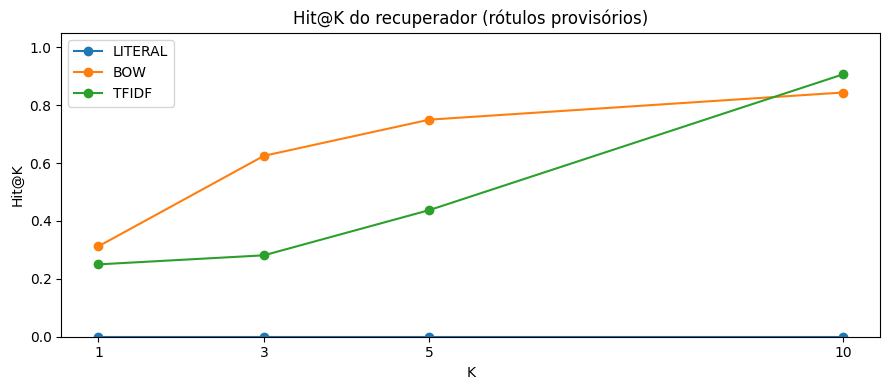

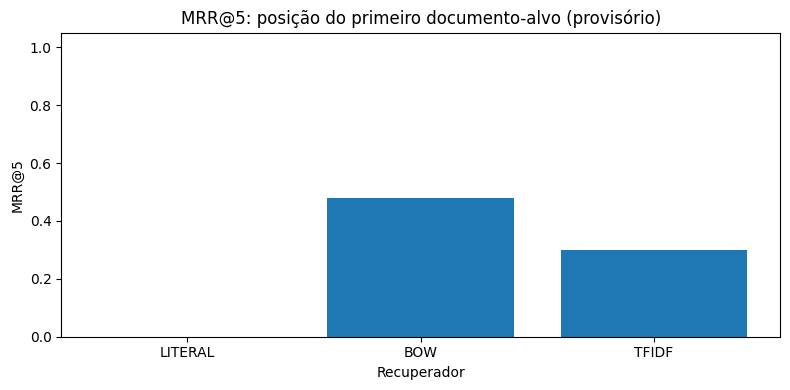

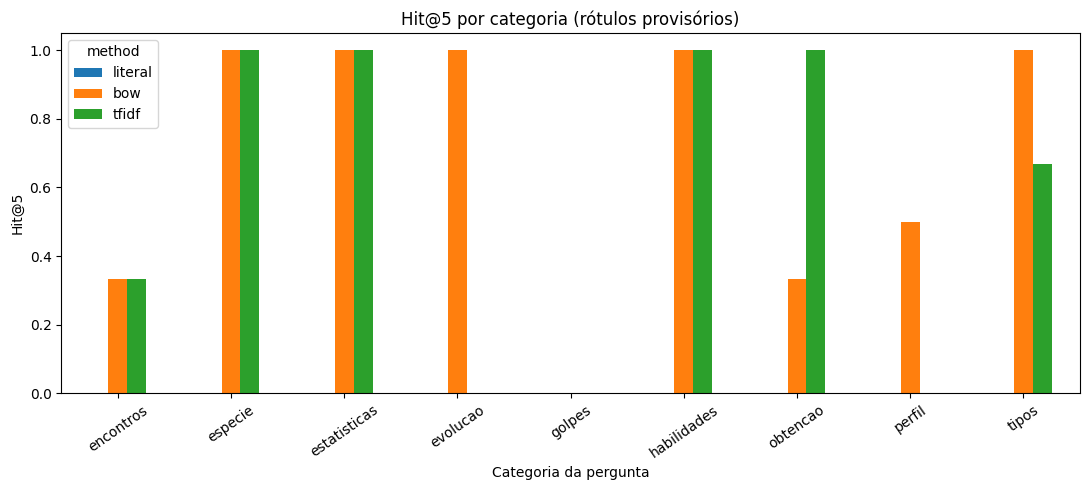

In [27]:
# Visualização 1 — Hit@K por estratégia (curvas).
fig, ax = plt.subplots(figsize=(9, 4))
for method in METHODS:
    part = metrics_summary.loc[metrics_summary['method']==method].sort_values('k')
    ax.plot(part['k'], part['hit_at_k'], marker='o', label=method.upper())
ax.set(title='Hit@K do recuperador (rótulos provisórios)', xlabel='K', ylabel='Hit@K', ylim=(0, 1.05))
ax.set_xticks(EVAL_KS)
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR/'01_retrieval_hit_at_k.png', dpi=150)
plt.show()

# Visualização 2 — MRR@5 por estratégia.
summary5 = metrics_summary[metrics_summary['k']==5].set_index('method').reindex(METHODS)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar([m.upper() for m in METHODS], summary5['mrr_at_k'])
ax.set(title='MRR@5: posição do primeiro documento-alvo (provisório)', xlabel='Recuperador', ylabel='MRR@5', ylim=(0, 1.05))
fig.tight_layout()
fig.savefig(FIG_DIR/'02_retrieval_mrr_at5.png', dpi=150)
plt.show()

# Visualização 3 — Hit@5 por categoria da pergunta.
by_category = metrics_df.query('k == 5').pivot_table(index='category', columns='method', values='hit_at_k')
by_category = by_category.reindex(columns=list(METHODS)).fillna(0)
fig, ax = plt.subplots(figsize=(11, 5))
by_category.plot(kind='bar', ax=ax)
ax.set(title='Hit@5 por categoria (rótulos provisórios)', xlabel='Categoria da pergunta', ylabel='Hit@5', ylim=(0, 1.05))
ax.tick_params(axis='x', labelrotation=35)
fig.tight_layout()
fig.savefig(FIG_DIR/'03_retrieval_hit_por_categoria.png', dpi=150)
plt.show()


## 8 · Análise de erros da busca TF-IDF

Para cada pergunta, verificamos a posição do primeiro documento-alvo, o que faltou entre os cinco primeiros, e quais seções foram recuperadas. Os erros podem surgir tanto da **recuperação** quanto de **rótulos incompletos**. Por isso, esta tabela fornece **casos para revisão**, não uma atribuição definitiva de falha ao modelo.

In [28]:
tfidf5 = metrics_df.query("method == 'tfidf' and k == 5").sort_values(
    ['hit_at_k','mrr_at_k','precision_at_k','query_id']
)
error_rows = []
for item in tfidf5.itertuples(index=False):
    top = rankings_df[(rankings_df['query_id']==item.query_id) & (rankings_df['method']=='tfidf')].sort_values('rank')
    found = set(top.loc[top['rank']<=5, 'document_id'])
    expected = set(qrels_by_query[item.query_id])
    error_rows.append({
        'query_id':item.query_id, 'question':item.question, 'category':item.category,
        'hit_at_5':item.hit_at_k, 'mrr_at_5':item.mrr_at_k,
        'expected_positive_documents':'; '.join(sorted(expected)),
        'missing_positive_in_top5':'; '.join(sorted(expected-found)),
        'top5_document_ids':'; '.join(top.loc[top['rank']<=5, 'document_id'].astype(str)),
        'top5_sections':'; '.join(top.loc[top['rank']<=5, 'section'].astype(str)),
        'review_note':'Conferir manualmente: outros trechos podem ser relevantes mesmo sem rótulo.'
    })
errors_df = pd.DataFrame(error_rows)
ERROR_PATH = REPORT_DIR / 'retrieval_error_analysis.csv'
errors_df.to_csv(ERROR_PATH, index=False, encoding='utf-8')
display(errors_df[['query_id','question','hit_at_5','mrr_at_5', 'missing_positive_in_top5']].head(12))

if not errors_df.empty:
    question = errors_df.iloc[0]['question']
    print('Exemplo para inspeção:', question)
    for row in search(question, 'tfidf', top_k=5, include_content=True):
        print(f"#{row['rank']} {row['document_id']} | score={row['score']:.3f}")
        print(row['content'][:350].replace('\n',' '))


,query_id,question,hit_at_5,mrr_at_5,missing_positive_in_top5
0,Q01,Quais são os tipos do Charizard?,0.0,0.0,006_profile
1,Q02,What type is Venusaur?,0.0,0.0,003_profile
2,Q05,Como o Eevee evolui?,0.0,0.0,133_evolution
3,Q06,Which Pokemon evolves from Charmander?,0.0,0.0,004_evolution
4,Q07,Quais são as fraquezas do Gyarados?,0.0,0.0,130_type_matchups
5,Q11,Quais golpes o Bulbasaur pode aprender?,0.0,0.0,001_moves_01; 001_moves_02; 001_moves_03
6,Q12,What moves does Pikachu learn in FireRed?,0.0,0.0,025_moves_01; 025_moves_02; 025_moves_03
7,Q13,Onde encontro Pikachu no FireRed?,0.0,0.0,025_encounters_01
8,Q14,Where can I find Zubat in FireRed?,0.0,0.0,041_encounters_01; 041_encounters_02; 041_enco...
9,Q15,Qual o habitat do Dratini?,0.0,0.0,147_profile


Exemplo para inspeção: Quais são os tipos do Charizard?
#1 006_abilities | score=0.395
Abilities of Charizard reconstructed for Generation III: - blaze (slot 1; generation_iii_reconstructed).
#2 006_obtainment | score=0.318
Acquisition evidence for Charizard in FireRed: Documented mechanisms: evolution. Complete game availability is NOT established from this dataset. No wild encounter entry does not imply unavailable; gifts, fossils, NPC trades and external trades need independently verified sources.
#3 006_species_traits | score=0.299
Species/breeding attributes of Charizard (PokéAPI species metadata): Egg groups: monster, dragon. Gender rate code: 1 (-1 means genderless). Growth rate: medium-slow. Color: red.
#4 006_type_matchups | score=0.259
Defensive effectiveness against Charizard (Generation III type chart): - 4x weak: rock. - 2x weak: electric, water. - 0.5x resistant: fighting, fire, steel. - 0.25x resistant: bug, grass. - immune (0x): ground. Type chart only: abilities and ba

## 9 · Persistência do recuperador para o Notebook 03

A exportação mantém os **nomes esperados pelo RAG**: `tfidf_vectorizer.joblib`, `tfidf_matrix.npz`, `bow_vectorizer.joblib`, `bow_matrix.npz` e `retrieval_manifest.json`. Também gravamos `query_normalization_rules.json`, para o terceiro notebook reproduzir as equivalências de consulta com **as mesmas regras**.

O manifesto inclui IDs na ordem indexada e o SHA-256 do arquivo de documentos, para detectar mudanças que invalidariam o alinhamento. A cada pergunta o Notebook 03 fará apenas **`transform`**, jamais `fit` novamente.

In [29]:
BOW_PATH = ARTIFACTS_DIR/'bow_vectorizer.joblib'
BOW_MATRIX_PATH = ARTIFACTS_DIR/'bow_matrix.npz'
TFIDF_PATH = ARTIFACTS_DIR/'tfidf_vectorizer.joblib'
TFIDF_MATRIX_PATH = ARTIFACTS_DIR/'tfidf_matrix.npz'
MANIFEST_PATH = ARTIFACTS_DIR/'retrieval_manifest.json'

joblib.dump(BOW,BOW_PATH)
joblib.dump(TFIDF,TFIDF_PATH)
sparse.save_npz(BOW_MATRIX_PATH,bow_matrix)
sparse.save_npz(TFIDF_MATRIX_PATH,tfidf_matrix)
manifest={
    'project':'Pokédex Inteligente — Kanto / FireRed',
    'run_at_utc':RUN_AT,
    'source_document_file':str(DOC_PATH),
    'source_document_sha256':hashlib.sha256(DOC_PATH.read_bytes()).hexdigest(),
    'document_count':len(documents),
    'document_ids':doc_ids,
    'normalization':'NFKD + casefold + diacritics/punctuation normalization; query alias substitution',
    'query_normalization_rules':QUERY_RULES_PATH.name,
    'aliases_file':str(ALIASES_PATH),
    'models':{
        'bow':{'vectorizer':BOW_PATH.name,'matrix':BOW_MATRIX_PATH.name,'ngram_range':[1,1]},
        'tfidf':{'vectorizer':TFIDF_PATH.name,'matrix':TFIDF_MATRIX_PATH.name,'ngram_range':[1,2]},
    },
    'evaluation':{
        'queries':str(QUERY_PATH),
        'qrels':str(QRELS_PATH),
        'label_status':'proxy structural relevance; manual review required',
        'k_values':list(EVAL_KS),
    }
}
MANIFEST_PATH.write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')

# Teste de recarregamento: garantir alinhamento de matriz e identificadores.
reloaded=joblib.load(TFIDF_PATH)
loaded_matrix=sparse.load_npz(TFIDF_MATRIX_PATH)
loaded_manifest=json.loads(MANIFEST_PATH.read_text(encoding='utf-8'))
assert loaded_matrix.shape[0]==len(loaded_manifest['document_ids'])==len(documents)
assert loaded_manifest['document_ids']==doc_ids
assert loaded_manifest['source_document_sha256']==hashlib.sha256(DOC_PATH.read_bytes()).hexdigest()
assert np.allclose(reloaded.transform([normalize_query('Charizard')]).toarray(),
                   TFIDF.transform([normalize_query('Charizard')]).toarray())
print('Artefatos de recuperação exportados e reabertos corretamente.')
for p in (BOW_PATH,BOW_MATRIX_PATH,TFIDF_PATH,TFIDF_MATRIX_PATH,MANIFEST_PATH,QUERY_RULES_PATH):
    print(f'{p.name}: {p.stat().st_size:,} bytes')
assert len(json.loads(QUERY_RULES_PATH.read_text(encoding='utf-8'))['rules']) == len(ALIAS_RULES)
assert all(did in DOC_INDEX for did in loaded_manifest['document_ids'])


Artefatos de recuperação exportados e reabertos corretamente.
bow_vectorizer.joblib: 25,713 bytes
bow_matrix.npz: 72,568 bytes
tfidf_vectorizer.joblib: 361,012 bytes
tfidf_matrix.npz: 863,511 bytes
retrieval_manifest.json: 38,679 bytes
query_normalization_rules.json: 4,285 bytes


## 10 · Relatório de resultados e próximos passos

**Este notebook demonstrará a recuperação textual**, enquanto o Notebook 03 avaliará a **qualidade factual das respostas** com fontes, abstenção quando o corpus não contém evidência e comparação entre pergunta e documentação.

**Para o relatório técnico:** descreva as técnicas originais no Trabalho 1 e neste notebook destaque somente as decisões novas: indexar trechos temáticos, escolher TF-IDF como candidato, ranquear Top-K, avaliar perguntas e registrar erros. Não extrapole o resultado de poucas consultas provisoriamente rotuladas para afirmar superioridade geral de um método.

In [ ]:
report = {
    'project':'Pokédex Inteligente — Trabalho 2',
    'notebook':'02_RETRIEVAL_AND_EVALUATION', 'run_utc':RUN_AT,
    'source_document_file':str(DOC_PATH),
    'source_document_sha256':hashlib.sha256(DOC_PATH.read_bytes()).hexdigest(),
    'document_count':len(documents), 'pokemon_count':len({int(d['pokemon_id']) for d in documents}),
    'model_index_dimensions': {'bow':list(bow_matrix.shape), 'tfidf':list(tfidf_matrix.shape)},
    'queries':len(queries), 'qrels':len(qrels),
    'label_status':queries['review_status'].value_counts().to_dict(),
    'metrics_macro_by_label_set':metrics_summary.to_dict(orient='records'),
    'literal_baseline':'Correspondência da pergunta normalizada completa; é deliberadamente restritiva.',
    'limitations':['Qrels proxy continuam exploratórios até revisão humana.',
                   'TF-IDF puro não mede o pipeline filtrado do chatbot (Notebook 03).'],
    'retrieval_manifest':str(MANIFEST_PATH), 'error_report':str(ERROR_PATH),
}
report_path = REPORT_DIR / 'retrieval_evaluation_report.json'
report_path.write_text(json.dumps(report, ensure_ascii=False, indent=2), encoding='utf-8')
print('Relatório:', report_path)


### Entregas para a próxima etapa

- **Para o RAG:** documento JSONL e índice TF-IDF (vetorizador, matriz, manifesto, aliases normalizados).
- **Para a avaliação acadêmica:** conjunto de consultas, qrels revisáveis, métricas por consulta, gráficos exclusivos de recuperação e relatório de erros.
- **Não duplicamos:** coleta, limpeza, lematização, POS tagging, BoW exploratório por Pokémon, esparsidade de N-grams ou os gráficos do Trabalho 1.

**Checklist antes do Notebook 03:** executar com os dados reais do Drive, revisar os rótulos de relevância, registrar limitações e conferir o SHA-256 do manifesto após qualquer mudança do corpus.